# 05: Stability

*How robust is the KG's predictive signal under edge loss?*

| Sub-metric | Definition | Quantification | Scoring |
|---|---|---|---|
| **Random-dropout stability** | Preservation of Adamic-Adar rankings under uniform random edge removal | Spearman *r* at every rate in `robustness.dropout_rates`, each the mean of `n_trials` draws | (*r* + 1) / 2 at `robustness.primary_dropout`, rescaled to [0, 1] |
| **Periphery-dropout stability** | The same, with edges removed lowest-degree-first | Spearman *r* at every rate, over `n_trials` seeded tie-break draws | (*r* + 1) / 2 at `robustness.primary_dropout`, rescaled to [0, 1] |

The dimension score is the equal-weighted mean of the two.

**Reported, not scored.** The same measurement on degree-matched random drug-disease pairs (the null), the Common Neighbors and Jaccard scorers beside Adamic-Adar, and top-K overlap.

**The null is what carries the biological claim.** Adamic-Adar is a function of shared-neighbour degrees, so a high absolute score on therapeutic pairs may only show that hub-driven rankings survive edge loss. Any claim that this dimension isolates biological signal has to be read against the gold-minus-null gap, not the absolute score.

**Rates, trials and the primary operating point all come from `config/params.yaml`.** Nothing about the sweep is written in this notebook; the notebook raises if `primary_dropout` is not among the configured rates.

**Thresholds** (interpretive, not used in scoring): *r* > 0.95 at the primary rate = high stability; *r* < 0.85 = fragile topology.

**Inputs:** `config/kgs.yaml` · `config/params.yaml` · KG edge and node files
**Outputs:** `results/{figures,tables}/05_stability/` · `results/checkpoints/05_stability.pkl`

Design notes and justifications: [`README.md`](README.md)

## Set-up

Every graph in `config/kgs.yaml` is loaded as a simple graph via `build_graph`, with each edge carrying the set of predicates asserting it and how many triples it holds. Dropout is drawn over triples rather than node pairs, so a redundantly asserted pair is harder to sever than a singly asserted one.

In [1]:
# Pick up edits to src/ without restarting the kernel. Without this, editing a
# module after it has been imported leaves the kernel holding the old version,
# which surfaces as a confusing ImportError for a name that is plainly on disk.
try:
    get_ipython().run_line_magic('load_ext', 'autoreload')
    get_ipython().run_line_magic('autoreload', '2')
except Exception:
    pass                      # not running under IPython (headless runner, plain python)

import gc
import sys
import warnings
from pathlib import Path
from collections import defaultdict

warnings.filterwarnings('ignore')

# Locate the repo root from any depth, then make the package importable.
# (`pip install -e .` also works and makes this block a no-op.)
_root = next(p for p in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
             if (p / 'config' / 'kgs.yaml').exists())
if str(_root / 'src') not in sys.path:
    sys.path.insert(0, str(_root / 'src'))

import numpy as np
import pandas as pd
import networkx as nx

from biokgsuite.graph.graph_utils import build_graph
from biokgsuite.graph.scoring import SCORERS
from biokgsuite.io import Outputs, assert_full_panel, find_config, load_config, load_kg, require
from biokgsuite.stats import stability as stab
from biokgsuite.viz.dimension05 import fig05_scorers, fig05_stability
from biokgsuite.viz.style import KG_PALETTE, setup_style

setup_style()

In [2]:
# Parameters are read with require(), never params.get(key, default): a silent
# default lets a run use a value config/params.yaml never mentions, which is how
# top_k and the dropout rates were applied for a whole project without appearing
# in the config at all.
config = load_config(find_config(_root))
params = config['analysis_params']
BASE   = config['_base_dir']

SEED            = require(params, 'random_seed')
DROPOUT_RATES   = list(require(params, 'dropout_rates', 'robustness'))
SAMPLE_SIZE     = require(params, 'sample_size', 'robustness')
TOP_K           = require(params, 'top_k', 'robustness')
N_TRIALS        = require(params, 'n_trials', 'robustness')
PRIMARY_DROPOUT = require(params, 'primary_dropout', 'robustness')

if PRIMARY_DROPOUT not in DROPOUT_RATES:
    raise ValueError(
        f'primary_dropout={PRIMARY_DROPOUT} is not among dropout_rates '
        f'{DROPOUT_RATES}. The dimension score is computed at that one rate, so '
        f'a mismatch would score every graph from a rate that was never run.')

# Every figure, table and checkpoint goes through `out`, so results land in
# results/{figures,tables}/05_stability/ and
# results/checkpoints/05_stability.pkl.
out = Outputs('05_stability', BASE)

# A run that scores fewer graphs than config/kgs.yaml declares is a
# different experiment, not a smaller one, so it has to be asked for.
ALLOW_PARTIAL_PANEL = False


### Loading

In [3]:
# Free any KG state left by an earlier notebook before loading again, so the
# two sets never coexist in the kernel.
for _v in ('kgs', 'graphs'):
    globals().pop(_v, None)
gc.collect()

KG_NAMES  = list(config['knowledge_graphs'].keys())
KG_COLORS = {n: KG_PALETTE.get(n, '#888888') for n in KG_NAMES}

kgs, graphs = {}, {}
for name in KG_NAMES:
    try:
        kg, nodes    = load_kg(name, config)
        G            = build_graph(kg, nodes)
        kgs[name]    = {'kg': kg, 'nodes': nodes}
        graphs[name] = G
        print(f'{name:12s}: {G.number_of_nodes():>8,} nodes  {G.number_of_edges():>10,} edges')
    except FileNotFoundError:
        print(f'{name:12s}: [NOT FOUND]')
    except Exception as e:
        print(f'{name:12s}: [ERROR] {e}')

LOADED = [n for n in KG_NAMES if n in graphs and config['knowledge_graphs'].get(n, {}).get('relations')]
print(f'\nLoaded: {LOADED}')
# Refuse to score a panel that is missing graphs.
#
# The broad `except` above keeps one unreadable graph from taking down the run,
# but the cost is that a run finding two of six completes, prints a dimension
# score and writes a checkpoint indistinguishable from a full one. Scores that
# intersect or normalise across the panel then differ from what a full run would
# give, silently. Set ALLOW_PARTIAL_PANEL in the config cell to score a subset
# deliberately; the reduced panel is recorded in the checkpoint either way.
PANEL = assert_full_panel(LOADED, config,
                          allow_partial=ALLOW_PARTIAL_PANEL,
                          notebook='05_stability')


primekg     : [NOT FOUND]


hetionet    :   47,031 nodes   2,107,709 edges
drkg        : [NOT FOUND]
openbilink  : [NOT FOUND]


biokg       :  105,524 nodes   2,043,846 edges
  matrix: keep_categories=all → retaining every typed node and edge
matrix      : [NOT FOUND]

Loaded: ['hetionet', 'biokg']


## 1. Therapeutic pair extraction

Stability is measured over **known therapeutic (drug-disease) pairs only**, not a mix of positives and random negatives. If known pair rankings are preserved under edge dropout, the underlying biological connectivity is robust. Negative pairs are excluded because their instability is uninformative: a random pair's score *should* change under perturbation.

Which relation counts as therapeutic, and which node labels count as a drug or a disease, are read from `config/kgs.yaml` rather than declared here, so every dimension in the benchmark agrees on both.

Pairs are restricted to the largest connected component. A pair with an endpoint outside it has no path to lose, so its ranking cannot degrade and it would make the graph look more stable than it is.

In [4]:
# Entity types come from config/kgs.yaml, not from a set written here.
#
# This notebook used to carry DRUG_TYPES = {'drug', 'Compound', 'compound',
# 'Drug'} and DISEASE_TYPES = {'disease', 'Disease'}. That is a second copy of
# `entity_types`, and it had already drifted: BioKG names diseases with both
# `Disease` (MeSH) and `GeneticDisorder` (OMIM), and the hardcoded set knew only
# the first. Reading the config is what makes every dimension agree about what a
# drug and a disease are.
ENTITY_TYPE_MAP = {n: config['knowledge_graphs'][n].get('entity_types', {})
                   for n in KG_NAMES}

def labels_for(name: str, canon: str) -> set:
    """KG-internal labels for a canonical entity type (always a tuple in config)."""
    return set(ENTITY_TYPE_MAP[name].get(canon, ()))

lcc_sets = {name: max(nx.connected_components(graphs[name]), key=len)
            for name in LOADED}

In [5]:
# Therapeutic relations come from config/kgs.yaml too.
#
# The KG_THERAPEUTIC table that used to live here was a second declaration of
# `relations.drug_disease`, and it had drifted for DRKG: the config names
# `DRUGBANK::treats::Compound:Disease`, the table matched the pattern
# `treat|indication`, which also pulls in GNBR treats edges the benchmark
# excludes. One source of truth, as in notebook 04.
def relation_labels(name: str, key: str) -> tuple:
    """Relation labels config declares for `key` on this KG.

    The config writes a single relation as `relation:` and several as
    `relations:`; both shapes are accepted.
    """
    spec = (config['knowledge_graphs'][name].get('relations') or {}).get(key)
    if not spec:
        return ()
    return tuple(spec['relations']) if 'relations' in spec else (spec['relation'],)

def extract_therapeutic_pairs(name: str) -> list:
    """(drug, disease) node-index pairs inside the LCC, oriented drug-first.

    Restricted to the largest component because a pair with an endpoint outside
    it has no path to lose, so its ranking cannot degrade and it would make the
    graph look more stable than it is.
    """
    rels = relation_labels(name, 'drug_disease')
    if not rels:
        return []
    drug, disease = labels_for(name, 'Drug'), labels_for(name, 'Disease')
    kg, lcc = kgs[name]['kg'], lcc_sets[name]
    sub = (kg[kg['relation'].isin(rels)][['x_index', 'y_index', 'x_type', 'y_type']]
           .astype({'x_index': int, 'y_index': int}))
    sub = sub[sub['x_index'].isin(lcc) & sub['y_index'].isin(lcc)]
    fwd = sub[sub['x_type'].isin(drug) & sub['y_type'].isin(disease)]
    rev = sub[sub['y_type'].isin(drug) & sub['x_type'].isin(disease)]
    # sorted, not list(set(...)): the pair order decides which pairs the sample
    # draws, so it has to be deterministic rather than set-iteration order.
    return sorted(set(list(zip(fwd['x_index'], fwd['y_index'])) +
                      list(zip(rev['y_index'], rev['x_index']))))

In [6]:
# Extract therapeutic pairs.
therapeutic_pairs = {name: extract_therapeutic_pairs(name) for name in LOADED}
for name, tp in therapeutic_pairs.items():
    print(f'{name:12s}: {len(tp):,} therapeutic pairs  '
          f'({", ".join(relation_labels(name, "drug_disease"))})')

_empty = [n for n, tp in therapeutic_pairs.items() if not tp]
if _empty:
    print(f'\nNo therapeutic pairs for {_empty}: these graphs are not scored. '
          f'That is an absence of the relation, not a stability finding.')

hetionet    : 755 therapeutic pairs  (CtD)
biokg       : 66,867 therapeutic pairs  (DRUG_DISEASE_ASSOCIATION)


## 2. Stability analysis

Two perturbation strategies, at every rate in `robustness.dropout_rates`, each applied to the therapeutic pairs and to a degree-matched null:

| Strategy | Description | Replication |
|---|---|---|
| **Random** | Edges removed uniformly at random; baseline robustness | `n_trials` draws, mean and SD reported |
| **Periphery** | Removed lowest-degree-first, fully ordered by (min degree, degree sum, endpoint indices) | deterministic, single pass |

| Pair set | Definition | Role |
|---|---|---|
| **Gold** | Known drug-disease pairs asserted by the KG, inside the LCC | scored |
| **Null** | Random drug-disease pairs, endpoint degrees matched to the gold pairs | reported |

Interpretive thresholds: *r* > 0.95 at the primary rate → high stability; *r* < 0.85 → fragile topology. Neither threshold means anything without the null beside it.

### Parameters and helpers

Metric helpers live in `biokgsuite.stats.stability`, beside `stats.topology` for notebook 04, so the definitions are importable and testable rather than resident in a notebook cell. See `tests/test_stability.py`.

In [7]:
# Edge-dropout strategies. Both are replicated: random removal is
# stochastic, and periphery ties are broken by a seeded shuffle inside
# each minimum-degree band, so both carry an uncertainty.
#
# Random dropout is stochastic by construction. Periphery dropout is
# deterministic given a tie-break, but two edges with the same minimum endpoint
# degree are equally peripheral by the metric's own definition, so which one goes
# first is arbitrary. Replicating it across seeded shuffles inside each degree
# band turns that arbitrariness into a standard deviation instead of hiding it
# behind a reproducible rule.
STRATEGIES = {
    'random':    'Random edge dropout',
    'periphery': 'Periphery-first dropout',
}

# All three neighbourhood scorers from biokgsuite.graph.scoring. Adamic-Adar is
# the scored one, as Table 1 states; Common Neighbors and Jaccard are reported
# beside it so a reviewer can see whether the conclusions are specific to AA's
# inverse-log-degree weighting. Reported, not scored, like NMI/ARI in notebook 04.
SCORED_BY = 'Adamic-Adar'
SCORER_NAMES = [SCORED_BY] + [s for s in SCORERS if s != SCORED_BY]

# Above this size a graph is perturbed with a filtered view rather than a copy.
LARGE_GRAPH_NODES = 1_000_000

print(f'rates {[f"{r:.0%}" for r in DROPOUT_RATES]}  primary {PRIMARY_DROPOUT:.0%}  '
      f'pairs {SAMPLE_SIZE}  trials {N_TRIALS} (both strategies)  top-K {TOP_K}')
print(f'scorers: {", ".join(SCORER_NAMES)}  (scored: {SCORED_BY})')

rates ['5%', '10%', '15%', '20%', '25%', '30%']  primary 10%  pairs 500  trials 3 (both strategies)  top-K 100
scorers: Adamic-Adar, Common Neighbors, Jaccard  (scored: Adamic-Adar)


### Robustness sweep

In [9]:
# Dropout robustness sweep.
#
# Every combination of {strategy} x {pair set} x {scorer} x {rate}, each the mean
# of N_TRIALS seeded draws. Results go into a flat record list rather than nested
# dicts: with four factors the nesting was the main source of indexing mistakes,
# and a DataFrame is what the tables and figures want anyway.
#
# Gold and null pairs are scored in ONE call per scorer per perturbed graph:
# each scorer rebuilds a per-node table over the whole graph, so scoring the two
# sets separately would pay that cost twice.
records, null_quality, graph_facts = [], {}, {}

for name in LOADED:
    tp = therapeutic_pairs.get(name)
    if not tp:
        continue

    G = graphs[name]
    edges, mult = stab.indexed_edges(G)
    n_edges, n_triples = len(edges), int(mult.sum())
    mult_by_edge = dict(zip(edges, mult))

    gold = [tp[i] for i in np.random.RandomState(SEED).choice(
        len(tp), min(SAMPLE_SIZE, len(tp)), replace=False)]
    lcc = lcc_sets[name]
    null = stab.degree_matched_pairs(
        G, gold,
        [v for v in lcc if G.nodes[v].get('node_type') in labels_for(name, 'Drug')],
        [v for v in lcc if G.nodes[v].get('node_type') in labels_for(name, 'Disease')],
        np.random.RandomState(SEED),
        # Every therapeutic pair in the graph, not only the sampled 500. Banning
        # just the sample leaves the rest eligible, so the null can contain real
        # indications and the gold-minus-null gap closes toward zero.
        exclude=set(tp) | {(v, u) for u, v in tp})
    null_quality[name] = stab.degree_match_quality(G, gold, null)

    split, both = len(gold), gold + null
    PAIR_SLICES = {'gold': slice(0, split), 'null': slice(split, None)}
    baselines = {}
    for sc in SCORER_NAMES:
        base = np.array(SCORERS[sc](G, both))
        baselines[sc] = {ps: base[sl] for ps, sl in PAIR_SLICES.items()}

    # Periphery order depends on the trial seed but not on the rate, so the
    # N_TRIALS orderings are built once and reused across the sweep.
    peri_orders = [stab.periphery_order(G, rng=np.random.RandomState(SEED + t))
                   for t in range(N_TRIALS)]

    graph_facts[name] = {'n_edges': n_edges, 'n_triples': n_triples,
                         'triples_per_pair': round(n_triples / n_edges, 3),
                         'gold_pairs': len(gold), 'null_pairs': len(null),
                         'therapeutic_pairs_available': len(tp)}
    print(f'{name}: {len(gold)} of {len(tp):,} therapeutic pairs | {len(null)} null '
          f"(median |log2 degree ratio| {null_quality[name]['median_abs_log2_ratio']}) | "
          f'{n_triples:,} triples over {n_edges:,} pairs '
          f'({n_triples / n_edges:.3f} per pair)')

    for rate in DROPOUT_RATES:
        severed = {}
        for strategy in STRATEGIES:
            vals, tks, neff = defaultdict(list), defaultdict(list), {}
            lost_counts = []
            for trial in range(N_TRIALS):
                trng = np.random.RandomState(SEED + trial)
                if strategy == 'random':
                    lost, spent = stab.triple_dropout(edges, mult, rate, trng)
                else:
                    lost, spent = stab.periphery_triples(
                        peri_orders[trial], mult_by_edge, rate, n_triples)
                lost_counts.append(len(lost))
                H = stab.without(G, lost)
                for sc in SCORER_NAMES:
                    pert = np.array(SCORERS[sc](H, both))
                    for ps, sl in PAIR_SLICES.items():
                        r, ne = stab.spearman(baselines[sc][ps], pert[sl])
                        vals[(ps, sc)].append(r)
                        tks[(ps, sc)].append(
                            stab.top_k_overlap(baselines[sc][ps], pert[sl], TOP_K))
                        neff[(ps, sc)] = ne
                    del pert
                del H
            severed[strategy] = int(np.mean(lost_counts))
            for (ps, sc), v in vals.items():
                records.append({
                    'KG': name, 'Strategy': STRATEGIES[strategy],
                    'strategy_key': strategy, 'Pair set': ps, 'Scorer': sc,
                    'Dropout': rate,
                    'Spearman r': round(float(np.mean(v)), 4),
                    'Spearman SD': round(float(np.std(v, ddof=1)), 4) if len(v) > 1 else 0.0,
                    'Pairs correlated': neff[(ps, sc)], 'Pairs sampled': SAMPLE_SIZE,
                    'Trials': N_TRIALS,
                    'Top-K overlap': round(float(np.mean(tks[(ps, sc)])), 3)
                                     if tks[(ps, sc)][0] == tks[(ps, sc)][0] else np.nan,
                })
        _aa = {(st_, ps): next(r for r in records
                               if r['KG'] == name and r['strategy_key'] == st_
                               and r['Pair set'] == ps and r['Scorer'] == SCORED_BY
                               and r['Dropout'] == rate)
               for st_ in STRATEGIES for ps in PAIR_SLICES}
        print(f"  {rate:>5.0%}  {int(round(rate * n_triples)):,} triples -> "
              f"{severed['random']:,} pairs severed at random, "
              f"{severed['periphery']:,} at the periphery"
              f"  |  {SCORED_BY}: random gold {_aa[('random','gold')]['Spearman r']:.4f}"
              f" (sd {_aa[('random','gold')]['Spearman SD']:.4f})"
              f"  periphery gold {_aa[('periphery','gold')]['Spearman r']:.4f}"
              f" (sd {_aa[('periphery','gold')]['Spearman SD']:.4f})")
    print()

stab_df = pd.DataFrame(records)

hetionet: 500 of 755 therapeutic pairs | 500 null (median |log2 degree ratio| 0.0266) | 2,250,197 triples over 2,107,709 pairs (1.068 per pair)


     5%  112,510 triples -> 98,489 pairs severed at random, 110,959 at the periphery  |  Adamic-Adar: random gold 0.9877 (sd 0.0027)  periphery gold 0.9822 (sd 0.0010)


    10%  225,020 triples -> 197,816 pairs severed at random, 219,476 at the periphery  |  Adamic-Adar: random gold 0.9752 (sd 0.0025)  periphery gold 0.9567 (sd 0.0000)


    15%  337,530 triples -> 297,900 pairs severed at random, 325,328 at the periphery  |  Adamic-Adar: random gold 0.9566 (sd 0.0021)  periphery gold 0.9385 (sd 0.0003)


    20%  450,039 triples -> 398,673 pairs severed at random, 428,918 at the periphery  |  Adamic-Adar: random gold 0.9374 (sd 0.0039)  periphery gold 0.9238 (sd 0.0002)


    25%  562,549 triples -> 500,173 pairs severed at random, 532,156 at the periphery  |  Adamic-Adar: random gold 0.9185 (sd 0.0065)  periphery gold 0.9095 (sd 0.0002)


... (4 outputs left out)

    15%  310,200 triples -> 303,584 pairs severed at random, 302,912 at the periphery  |  Adamic-Adar: random gold 0.9964 (sd 0.0002)  periphery gold 0.9945 (sd 0.0000)


    20%  413,600 triples -> 405,022 pairs severed at random, 404,638 at the periphery  |  Adamic-Adar: random gold 0.9951 (sd 0.0004)  periphery gold 0.9886 (sd 0.0000)


    25%  517,000 triples -> 506,544 pairs severed at random, 506,168 at the periphery  |  Adamic-Adar: random gold 0.9937 (sd 0.0004)  periphery gold 0.9813 (sd 0.0000)


    30%  620,399 triples -> 608,201 pairs severed at random, 607,096 at the periphery  |  Adamic-Adar: random gold 0.9916 (sd 0.0004)  periphery gold 0.9453 (sd 0.0000)



In [10]:
# Release the per-KG edge tables. The sweep above is the last thing that reads
# them (via extract_therapeutic_pairs); everything downstream works on
# graphs[name] only, and the DataFrames are the largest objects in the kernel.
for _name in list(kgs):
    kgs[_name].pop('kg', None)
gc.collect()
print("Released kgs[*]['kg'] edge tables.")

Released kgs[*]['kg'] edge tables.


## Dimension score

$$\text{Stability} = \tfrac{1}{2}\left(\text{Random-dropout stability} + \text{Periphery-dropout stability}\right)$$

Each sub-metric is Spearman $r$ at the pre-specified primary dropout rate, linearly rescaled to $[0, 1]$:

$$\text{Sub-score} = \frac{r_{\text{primary}} + 1}{2}$$

This is a rescaling, not a probability. $(r + 1) / 2$ is the probability of concordance only for **Kendall's $\tau$**; for Spearman's $\rho$ it has no such reading, and the Common Language Effect Size is a third quantity again (the probability that a draw from one group exceeds a draw from another), so neither name applies here. What the transformation does give is a common scale with the other dimensions and a **chance floor of 0.5**: a graph whose rankings are destroyed scores 0.5, and only perfect rank inversion reaches 0. It is monotonic in $r$, so it does not reorder the graphs.

The primary rate is a moderate incompleteness regime consistent with estimates of missing edges in published biomedical KGs (Paulheim, 2017) — large enough to expose genuine fragility, small enough to stay realistic. The full degradation profile across every configured rate is the supporting evidence that the primary score is representative, and is stored in the checkpoint, written to `stability.csv`, and drawn in the figure.

A graph whose Spearman $r$ is undefined is **not** scored 0. Too few pairs carrying Adamic-Adar signal is a broken measurement, not a maximally unstable graph, and the notebook raises rather than recording it as the worst possible result.

In [11]:
# Scores, degradation profile and checkpoint, all derived from `stab_df`.
def pick(kg, strategy, pair_set, scorer, rate, col='Spearman r'):
    m = stab_df[(stab_df.KG == kg) & (stab_df.strategy_key == strategy)
                & (stab_df['Pair set'] == pair_set) & (stab_df.Scorer == scorer)
                & (stab_df.Dropout == rate)]
    return m[col].iloc[0]

# A graph that could not be scored is a broken run, not a fragile graph. This
# used to fall back to 0.0, which is indistinguishable from a real result and
# below the 0.5 chance floor the rescaled correlation actually has.
_undef = stab_df[(stab_df['Pair set'] == 'gold') & (stab_df.Scorer == SCORED_BY)
                 & stab_df['Spearman r'].isna()]
if len(_undef):
    raise RuntimeError(
        'Spearman r is undefined for:\n' + _undef[['KG', 'Strategy', 'Dropout']].to_string()
        + '\nToo few therapeutic pairs carry signal to correlate. Raise sample_size or '
          'exclude the graph explicitly, rather than recording it as maximally unstable.')

SCORED = sorted(stab_df.KG.unique(), key=list(LOADED).index)

raw_r      = {kg: {s: {r: pick(kg, s, 'gold', SCORED_BY, r) for r in DROPOUT_RATES}
                   for s in STRATEGIES} for kg in SCORED}
raw_r_null = {kg: {s: {r: pick(kg, s, 'null', SCORED_BY, r) for r in DROPOUT_RATES}
                   for s in STRATEGIES} for kg in SCORED}

sub_scores = {kg: {f'{s}_stability': stab.cles(pick(kg, s, 'gold', SCORED_BY, PRIMARY_DROPOUT))
                   for s in STRATEGIES} for kg in SCORED}
summary_scores = {kg: round(float(np.mean(list(v.values()))), 4)
                  for kg, v in sub_scores.items()}

# Degradation profile at every rate, scored metric, gold above its null.
_hdr = '  '.join(f'{r:>7.0%}' + ('*' if r == PRIMARY_DROPOUT else ' ') for r in DROPOUT_RATES)
print(f'{SCORED_BY}: Spearman r by dropout rate (* = the rate scored).\n')
print(f'  {"":<26s}{_hdr}')
for kg in SCORED:
    print(f'  {kg.upper()}')
    for s, label in STRATEGIES.items():
        for ps, src in (('gold', raw_r), ('null', raw_r_null)):
            print(f'  {label + " / " + ps:<26s}'
                  + '  '.join(f'{src[kg][s][r]:>7.4f} ' for r in DROPOUT_RATES))
print()

# Gold minus null, both strategies. They disagree in sign and that is the finding.
gap = {kg: {s: round(pick(kg, s, 'gold', SCORED_BY, PRIMARY_DROPOUT)
                     - pick(kg, s, 'null', SCORED_BY, PRIMARY_DROPOUT), 4)
            for s in STRATEGIES} for kg in SCORED}
print(f'Gold minus degree-matched null at the primary rate ({PRIMARY_DROPOUT:.0%}), {SCORED_BY}:')
print(f'  {"KG":<12s}' + ''.join(f'{l:>26s}' for l in STRATEGIES.values()))
for kg in SCORED:
    print(f'  {kg:<12s}' + ''.join(f'{gap[kg][s]:>+26.4f}' for s in STRATEGIES))
print()
print('Positive means the therapeutic pairing carries robustness the degree')
print('distribution alone does not. Near zero means the stability measured is mostly')
print('degree-driven; negative means therapeutic pairs are MORE fragile than')
print('degree-matched ones under that perturbation. Reported, not scored.')
print('Null correlations rest on fewer pairs than gold, so the two are not estimated')
print('from equal n; both counts are in stability.csv.')
print()

# Scorer agreement: is any of this specific to Adamic-Adar's weighting?
print(f'Scorer comparison at the primary rate, therapeutic pairs, random dropout:')
print(f'  {"KG":<12s}' + ''.join(f'{sc:>20s}' for sc in SCORER_NAMES))
for kg in SCORED:
    print(f'  {kg:<12s}' + ''.join(
        f"{pick(kg, 'random', 'gold', sc, PRIMARY_DROPOUT):>20.4f}" for sc in SCORER_NAMES))
print(f'  {"":<12s}' + ''.join(f'{"(scored)" if sc == SCORED_BY else "(reported)":>20s}'
                               for sc in SCORER_NAMES))
print()

scores_df = pd.DataFrame([{'KG': kg, 'stability': summary_scores[kg], **sub_scores[kg],
                           **{f'gold - null ({s})': gap[kg][s] for s in STRATEGIES}}
                          for kg in SCORED]).set_index('KG')
out.table(scores_df.reset_index(), 'dimension_scores')
display(scores_df)

out.table(stab_df.drop(columns=['strategy_key']), 'stability')
out.checkpoint({
    'summary_scores': summary_scores, 'sub_scores': sub_scores,
    'raw_r': raw_r, 'raw_r_null': raw_r_null, 'gold_minus_null': gap,
    'null_quality': null_quality, 'graph_facts': graph_facts,
    'scored_by': SCORED_BY, 'scorers': SCORER_NAMES,
    'primary_dropout': PRIMARY_DROPOUT, 'dropout_rates': DROPOUT_RATES,
    'n_trials': N_TRIALS, 'sample_size': SAMPLE_SIZE, 'top_k': TOP_K, 'seed': SEED,
    'stab_records': stab_df.drop(columns=['strategy_key']).to_dict('records'),
})
print(out.summary())

Adamic-Adar: Spearman r by dropout rate (* = the rate scored).

                                 5%       10%*      15%       20%       25%       30% 
  HETIONET
  Random edge dropout / gold 0.9877    0.9752    0.9566    0.9374    0.9185    0.8994 
  Random edge dropout / null 0.9819    0.9566    0.9395    0.9094    0.8912    0.8764 
  Periphery-first dropout / gold 0.9822    0.9567    0.9385    0.9238    0.9095    0.8755 
  Periphery-first dropout / null 0.9982    0.9877    0.9811    0.9751    0.9699    0.9504 
  BIOKG
  Random edge dropout / gold 0.9989    0.9976    0.9964    0.9951    0.9937    0.9916 
  Random edge dropout / null 0.9983    0.9963    0.9938    0.9907    0.9882    0.9854 
  Periphery-first dropout / gold 0.9999    0.9987    0.9945    0.9886    0.9813    0.9453 
  Periphery-first dropout / null 1.0000    1.0000    0.9973    0.9925    0.9894    0.9515 

Gold minus degree-matched null at the primary rate (10%), Adamic-Adar:
  KG                 Random edge dropout   Per

,stability,random_stability,periphery_stability,gold - null (random),gold - null (periphery)
KG,,,,,
hetionet,0.983,0.9876,0.9784,0.0186,-0.0310
biokg,0.999,0.9988,0.9993,0.0013,-0.0013


05_stability: wrote 3 files
  results/checkpoints/05_stability.pkl
  results/tables/05_stability/dimension_scores.csv
  results/tables/05_stability/stability.csv


### Visualisation and export

  → Saved: stability.pdf / .png  (300 dpi)
  → Saved: scorer_agreement.pdf / .png  (300 dpi)


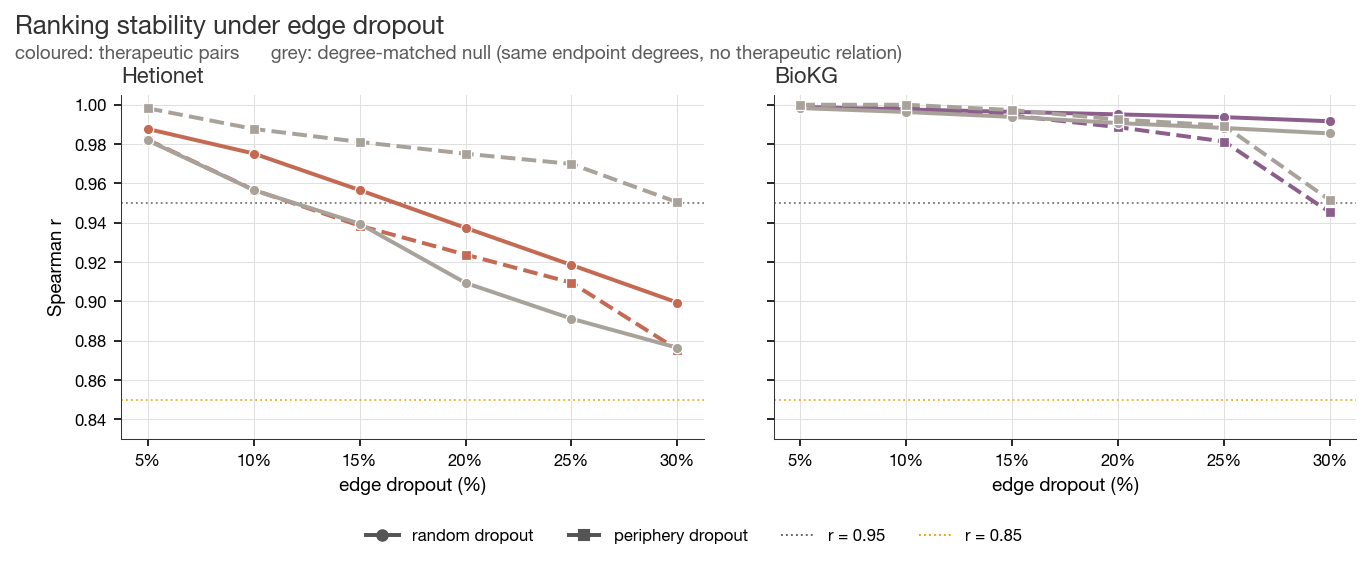

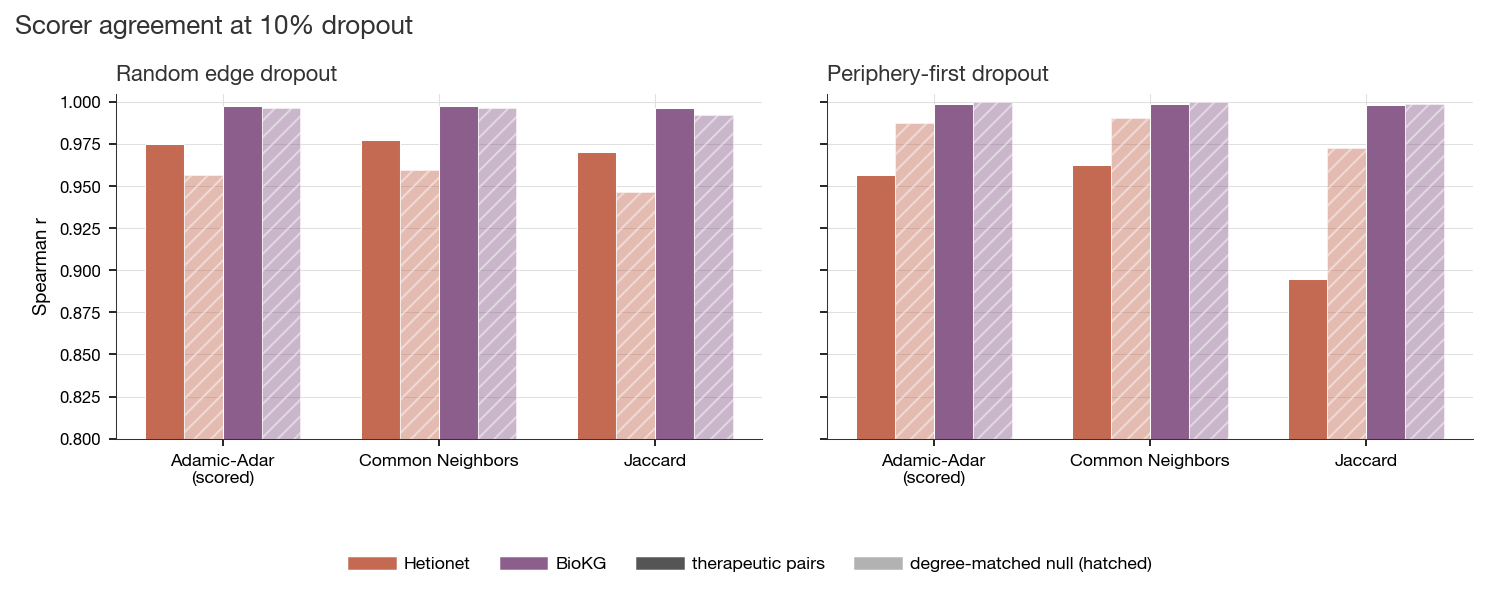

In [12]:
out.figure(fig05_stability(raw_r, DROPOUT_RATES, raw_r_null), 'stability');
out.figure(fig05_scorers(stab_df, PRIMARY_DROPOUT, SCORER_NAMES, SCORED_BY),
           'scorer_agreement');

In [13]:
# Free KG state before the next notebook, which loads the same graphs again.
# Without this both sets stay resident and the kernel is OOM-killed.
for _v in ('kgs', 'graphs'):
    globals().pop(_v, None)
print(f'Released KG state; {gc.collect():,} objects collected.')
print('\nStability: ' + '  '.join(f'{k} {v:.4f}' for k, v in summary_scores.items()))

Released graph state; 2,167,730 objects collected.

Stability: hetionet 0.9830  biokg 0.9990
